has_diabetes
0    1737
1     263
Name: count, dtype: int64
Saved: outputs/diabetes_distribution.png


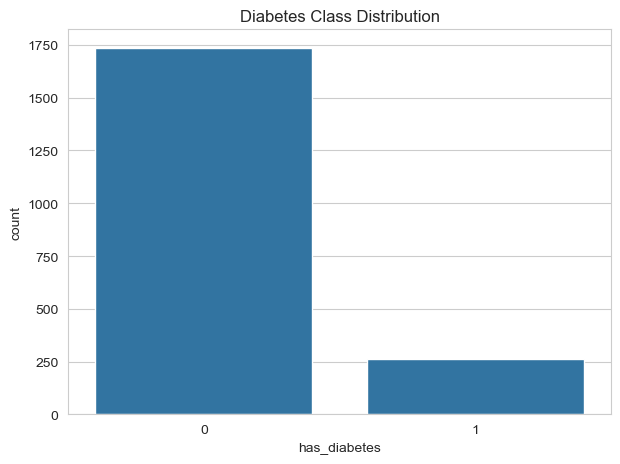


✅ Model Trained Successfully!
Saved: outputs/confusion_matrix.png


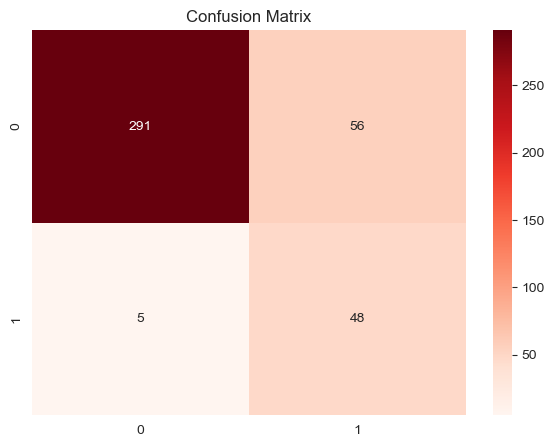

Saved: outputs/roc_curve.png


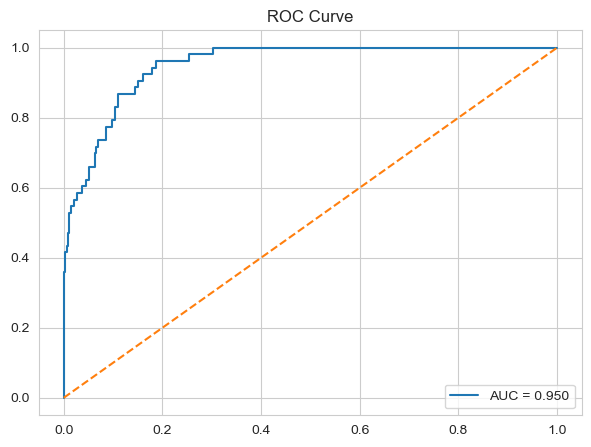

Saved: outputs/feature_importance.png


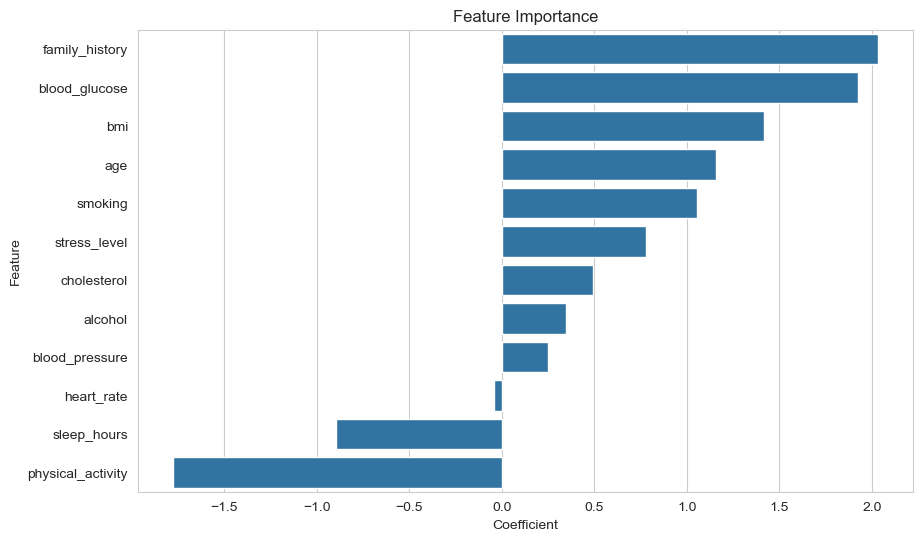

Dataset saved successfully!


In [4]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# ============================================================
# STYLE SETTINGS
# ============================================================

sns.set_style("whitegrid")
np.random.seed(42)

# ============================================================
# AUTO SAVE SETUP (FIXED)
# ============================================================

os.makedirs("outputs", exist_ok=True)

def save_plot(name):
    path = f"outputs/{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved: {path}")

# ============================================================
# CREATE DATASET
# ============================================================

n = 2000

df = pd.DataFrame({

    "age": np.random.randint(20, 85, n),
    "bmi": np.random.uniform(16, 45, n).round(1),
    "blood_glucose": np.random.randint(70, 320, n),
    "blood_pressure": np.random.randint(60, 180, n),
    "cholesterol": np.random.randint(120, 350, n),
    "heart_rate": np.random.randint(55, 120, n),
    "physical_activity": np.random.randint(0, 7, n),
    "sleep_hours": np.random.uniform(3, 10, n).round(1),
    "stress_level": np.random.randint(1, 10, n),
    "family_history": np.random.randint(0, 2, n),
    "smoking": np.random.randint(0, 2, n),
    "alcohol": np.random.randint(0, 2, n)
})

# ============================================================
# RISK SCORE + TARGET
# ============================================================

risk_score = (

    df["age"] * 0.03 +
    df["bmi"] * 0.08 +
    df["blood_glucose"] * 0.015 +
    df["blood_pressure"] * 0.005 +
    df["cholesterol"] * 0.004 +
    df["stress_level"] * 0.15 +
    df["family_history"] * 2 +
    df["smoking"] * 1 +
    df["alcohol"] * 0.5 +
    df["physical_activity"] * -0.4 +
    df["sleep_hours"] * -0.2 +
    np.random.normal(0, 1, n)
)

df["has_diabetes"] = (risk_score > 11).astype(int)

# ============================================================
# DATA CHECK
# ============================================================

print(df["has_diabetes"].value_counts())

# ============================================================
# VISUALIZATION 1 — CLASS DISTRIBUTION (FIXED SAVE ORDER)
# ============================================================

plt.figure(figsize=(7,5))
sns.countplot(data=df, x="has_diabetes")
plt.title("Diabetes Class Distribution")

save_plot("diabetes_distribution")
plt.show()

# ============================================================
# FEATURES & TARGET
# ============================================================

X = df.drop("has_diabetes", axis=1)
y = df["has_diabetes"]

# ============================================================
# SPLIT DATA
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ============================================================
# SCALING
# ============================================================

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ============================================================
# MODEL
# ============================================================

model = LogisticRegression(
    random_state=42,
    max_iter=2000,
    class_weight="balanced"
)

model.fit(X_train_scaled, y_train)

print("\n✅ Model Trained Successfully!")

# ============================================================
# PREDICTIONS
# ============================================================

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:,1]

# ============================================================
# CONFUSION MATRIX (SAVED PROPERLY)
# ============================================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")
plt.title("Confusion Matrix")

save_plot("confusion_matrix")
plt.show()

# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],"--")
plt.title("ROC Curve")
plt.legend()

save_plot("roc_curve")
plt.show()

# ============================================================
# FEATURE IMPORTANCE
# ============================================================

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
}).sort_values("Coefficient", ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(data=coef_df, x="Coefficient", y="Feature")
plt.title("Feature Importance")

save_plot("feature_importance")
plt.show()

# ============================================================
# SAVE DATASET
# ============================================================

df.to_csv("hospital_diabetes_dataset.csv", index=False)
print("Dataset saved successfully!")